## How to run in Colab
1. I open [Google Colab](https://colab.research.google.com) → **File → Upload notebook** → I choose this file.
2. The dataset: `Superstore Dataset (vivek468).zip` is in my `C:\Users\sivan\Datasets` folder.
3. When the upload cell asks for a file, I choose `Superstore Dataset (vivek468).zip`.
4. I run the cells from top to bottom (Shift+Enter runs one cell). After a restart I run them again from the top.

**About the data file:** the exercise gives the data as an Excel file, `US Superstore data.xls`. The same data (same 9,994 rows and 21 columns, same totals) is also on Kaggle as a CSV file ([US Superstore – vivek468](https://www.kaggle.com/datasets/vivek468/superstore-dataset-final)). I already had that CSV zipped in my Datasets folder, so I use the CSV. I checked that both files have the same rows, columns and totals.

# Mini-Project : Data Analysis for Marketing Strategy

In this mini project I analyse US Superstore orders to decide which states and cities to focus marketing on. I use what I learned in Week 2: pandas cleaning, `groupby`, sorting, and Matplotlib/Seaborn charts.

**My steps:**
1. Import the libraries
2. Load and clean the data
3. States with the most sales
4. New York vs California
5. Outstanding customer in New York
6. Profitability differences among states
7. Pareto: customers and profit
8. Top 20 cities by sales and by profit
9. Top 20 customers by sales
10. Cumulative sales curve and Pareto for sales
11. My decisions

## Step 1. Import the libraries

In [1]:
import pandas as pd
# pandas: for tables (DataFrames)
import numpy as np
# numpy: for number calculations
import matplotlib.pyplot as plt
# matplotlib: for drawing charts
import seaborn as sns
# seaborn: nicer charts built on matplotlib
sns.set_theme(style='whitegrid')
# I give all charts a white background with grid lines

## Step 2. Load and clean the data
**What I want to find:** how big the data is, if anything is missing or duplicated, and the dates as real dates.

In [ ]:
from google.colab import files
# I import the Colab tool for uploading files from my computer
uploaded = files.upload()
# I choose "Superstore Dataset (vivek468).zip" (I save it in a variable so its contents are not printed)
!unzip "Superstore Dataset (vivek468).zip"
# I unzip it: I get the file "superstore_dataset.csv"

In [3]:
df = pd.read_csv('superstore_dataset.csv', encoding='latin1')
# I read the CSV into a table; encoding='latin1' because the file has characters that are not UTF-8 (without it I get an error)
# df = pd.read_excel('US Superstore data.xls')
# (how I would read the Excel version instead; for an old .xls file pandas needs the xlrd library)
print(df.shape)
# I print (rows, columns)
df.head()
# I show the first 5 rows

(9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [4]:
df.info()
# I see each column's name, data type and how many values are not empty

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [5]:
print(df.isnull().sum().sum())
# isnull() marks empty cells, the two sum() count them in the whole table
print(df.duplicated().sum())
# duplicated() marks rows that are exact copies of an earlier row; sum() counts them
df = df.drop_duplicates()
# I remove copied rows (there are none, but it is a standard cleaning step)
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%m/%d/%Y')
# I turn the date text (month/day/year) into real dates
df['Ship Date'] = pd.to_datetime(df['Ship Date'], format='%m/%d/%Y')
# the same for the ship date
df['Year'] = df['Order Date'].dt.year
# .dt.year takes the year out of each date: a new column 'Year'
df['Month'] = df['Order Date'].dt.month
# .dt.month takes the month number (1-12): a new column 'Month'
df[['Sales', 'Quantity', 'Discount', 'Profit']].describe()
# describe() gives count, mean, min, max etc. of the number columns

0
0


,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000


**What the result shows:** the table has 9,994 rows and 21 columns, with no missing values and no duplicates. The dates were text, so I converted them and added Year and Month columns.

## Step 3. Which states have the most sales?
**What I want to find:** the total sales of each state, and the 10 biggest.

In [6]:
state = df.groupby('State')[['Sales', 'Profit']].sum()
# groupby('State') makes one group per state; sum() adds up Sales and Profit in each group
state = state.sort_values('Sales', ascending=False)
# I sort by Sales; ascending=False puts the biggest first
state.head(10)
# I show the top 10 states

,Sales,Profit
State,,
California,457687.6315,76381.3871
New York,310876.2710,74038.5486
Texas,170188.0458,-25729.3563
Washington,138641.2700,33402.6517
Pennsylvania,116511.9140,-15559.9603
Florida,89473.7080,-3399.3017
Illinois,80166.1010,-12607.8870
Ohio,78258.1360,-16971.3766
Michigan,76269.6140,24463.1876


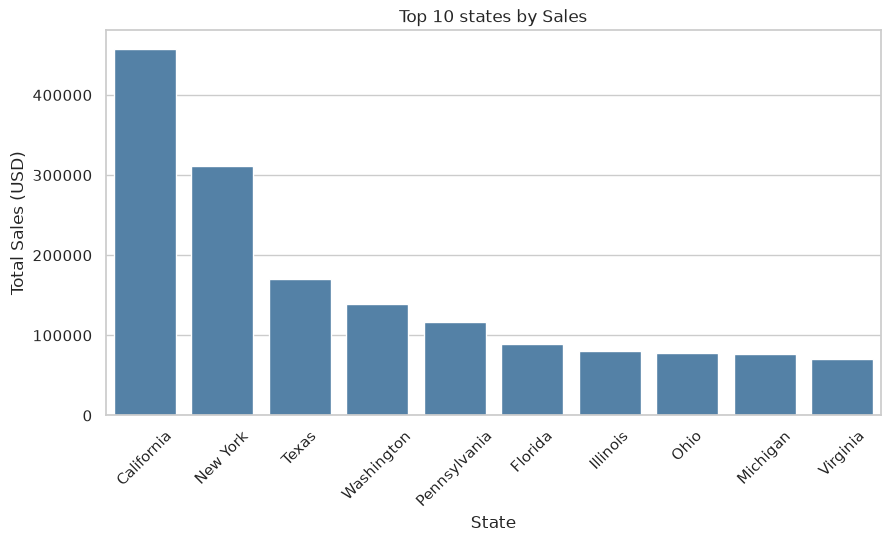

In [7]:
plt.figure(figsize=(10, 5))
# I set the chart size (width, height in inches)
sns.barplot(x=state.head(10).index, y=state.head(10)['Sales'], color='steelblue')
# a bar per state: x = state names (the index), y = their sales, all bars one color
plt.xticks(rotation=45)
# I turn the names 45 degrees so they don't overlap
plt.title('Top 10 states by Sales')
# chart title
plt.ylabel('Total Sales (USD)')
# y-axis label
plt.show()
# I display the chart

**What the result shows:** California has the most sales (about \$457,688), then New York (\$310,876) and Texas (\$170,188).

## Step 4. New York vs California
**What I want to find:** the total sales and total profit of the two states, side by side.

In [8]:
ny_ca = state.loc[['New York', 'California']]
# .loc picks rows by their label: only these two states
ny_ca['Margin %'] = ny_ca['Profit'] / ny_ca['Sales'] * 100
# profit margin = how many cents of profit from each dollar of sales, in percent
ny_ca.round(1)
# I show the table, rounded to 1 decimal

,Sales,Profit,Margin %
State,,,
New York,310876.3,74038.5,23.8
California,457687.6,76381.4,16.7


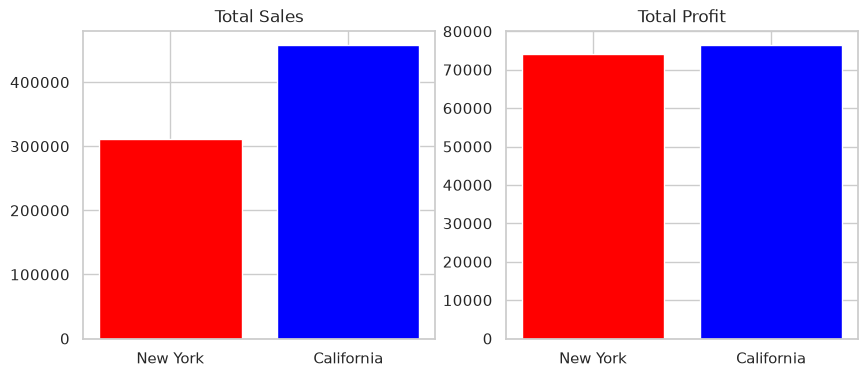

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
# I make 1 row with 2 charts next to each other
axes[0].bar(ny_ca.index, ny_ca['Sales'], color=['red', 'blue'])
# left chart: sales of each state
axes[0].set_title('Total Sales')
# left title
axes[1].bar(ny_ca.index, ny_ca['Profit'], color=['red', 'blue'])
# right chart: profit of each state
axes[1].set_title('Total Profit')
# right title
plt.show()
# I display the charts

**What the result shows:** California sells about \$147,000 more than New York, but the profit is almost the same (\$76,381 vs \$74,039). New York keeps 23.8% of its sales as profit, California only 16.7%, so New York is the more efficient market.

## Step 5. Who is an outstanding customer in New York?
**What I want to find:** the New York customers with the highest sales and profit.

In [10]:
ny = df[df['State'] == 'New York']
# I keep only the rows where State is New York
ny_cust = ny.groupby('Customer Name')[['Sales', 'Profit']].sum()
# total sales and profit of each New York customer
top_ny = ny_cust.sort_values('Sales', ascending=False).head(10)
# the 10 customers with the most sales
top_ny

,Sales,Profit
Customer Name,,
Tom Ashbrook,13723.498,4599.2073
Peter Fuller,7678.228,543.2819
Seth Vernon,7359.918,1571.7964
Tom Boeckenhauer,6999.960,2239.9872
Greg Tran,6712.744,774.7935
Todd Sumrall,6492.314,1574.9714
Karen Daniels,6241.282,2283.0463
Keith Dawkins,5854.194,2510.8903
Luke Weiss,5048.186,773.1004


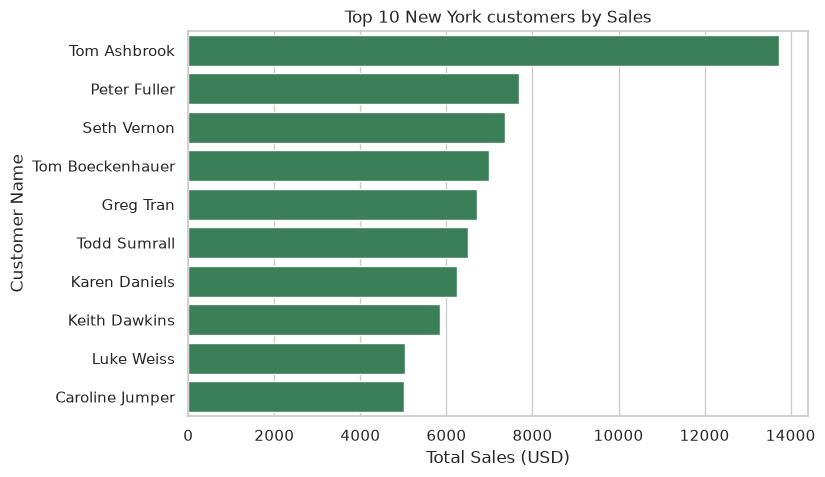

In [11]:
plt.figure(figsize=(8, 5))
# chart size
sns.barplot(x=top_ny['Sales'], y=top_ny.index, color='seagreen')
# horizontal bars: names on the y-axis, sales on the x-axis
plt.title('Top 10 New York customers by Sales')
# chart title
plt.xlabel('Total Sales (USD)')
# x-axis label
plt.show()
# I display the chart

**What the result shows:** **Tom Ashbrook** is the outstanding customer: \$13,723 in sales, almost double the next customer (Peter Fuller, \$7,678), and also the highest profit (\$4,599).

## Step 6. Are there differences among states in profitability?
**What I want to find:** which states make a profit and which lose money.

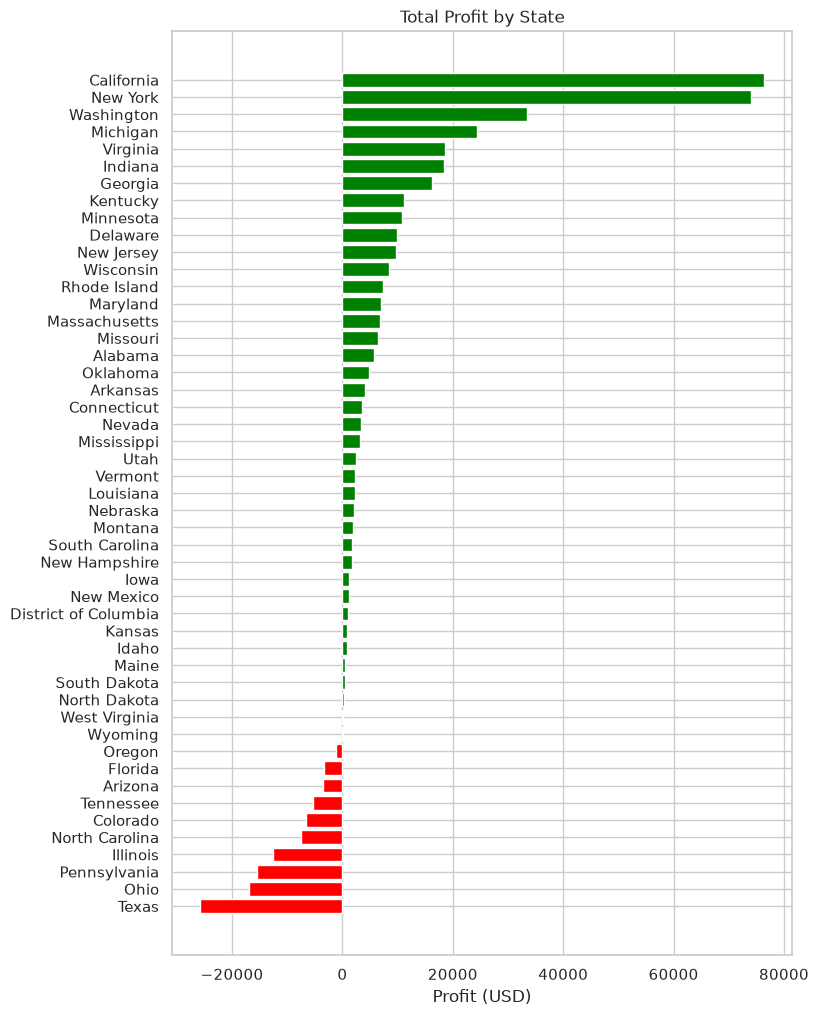

In [12]:
state_profit = state.sort_values('Profit')
# I sort the states from the lowest to the highest profit
colors = ['red' if p < 0 else 'green' for p in state_profit['Profit']]
# a list comprehension: red for a loss, green for a profit
plt.figure(figsize=(8, 12))
# a tall chart so all 49 states fit
plt.barh(state_profit.index, state_profit['Profit'], color=colors)
# barh = horizontal bars: one per state, colored by my list
plt.title('Total Profit by State')
# chart title
plt.xlabel('Profit (USD)')
# x-axis label
plt.show()
# I display the chart

In [13]:
print((state['Profit'] < 0).sum())
# True for each state with a loss; sum() counts the Trues
state_profit.head(5)
# the 5 states with the biggest losses

10


,Sales,Profit
State,,
Texas,170188.0458,-25729.3563
Ohio,78258.1360,-16971.3766
Pennsylvania,116511.9140,-15559.9603
Illinois,80166.1010,-12607.8870
North Carolina,55603.1640,-7490.9122


**What the result shows:** yes, the differences are big. 10 states lose money. Texas (−\$25,729), Ohio, Pennsylvania and Illinois lose the most, even though Texas and Pennsylvania are in the top 5 for sales. California and New York make the most profit.

## Step 7. Pareto: do 20% of the customers make 80% of the profit?
**What I want to find:** what share of the total profit the best 20% of customers bring.

In [14]:
cust = df.groupby('Customer Name')[['Sales', 'Profit']].sum()
# total sales and profit of each customer
print(len(cust))
# len() = number of customers
cust_profit = cust['Profit'].sort_values(ascending=False)
# customers' profits, best first
cum_profit = cust_profit.cumsum() / cust_profit.sum() * 100
# cumsum() adds the values one by one (running total); I divide by the total to get percent
top20 = int(len(cust) * 0.2)
# 20% of the customers; int() cuts off the decimals
print(top20, cum_profit.iloc[top20 - 1])
# .iloc picks by position: the running total after the top 20% customers

793
158 81.42587496747001


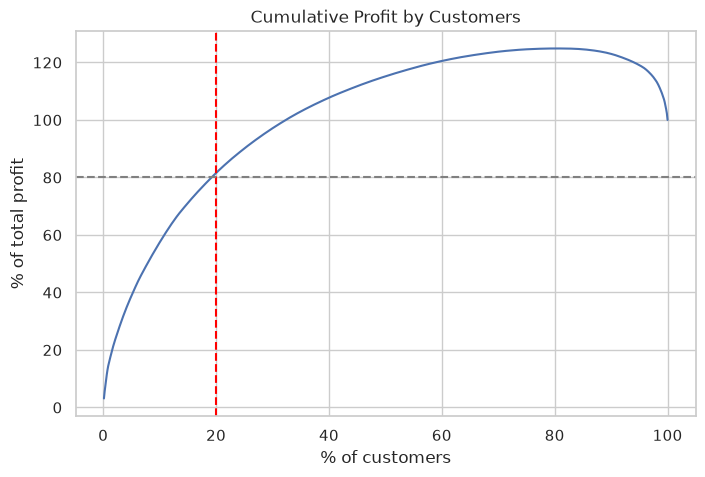

In [15]:
x = np.arange(1, len(cust) + 1) / len(cust) * 100
# np.arange(1, 794) gives 1, 2, ... 793; I turn it into "% of customers"
plt.figure(figsize=(8, 5))
# chart size
plt.plot(x, cum_profit.values)
# the line: % of customers vs % of profit
plt.axvline(20, color='red', linestyle='--')
# axvline = vertical line at 20% of customers, dashed
plt.axhline(80, color='gray', linestyle='--')
# axhline = horizontal line at 80% of profit
plt.title('Cumulative Profit by Customers')
# chart title
plt.xlabel('% of customers')
# x-axis label
plt.ylabel('% of total profit')
# y-axis label
plt.show()
# I display the chart

**What the result shows:** yes. The best 20% of customers (158 of 793) bring about 81% of the profit, so the Pareto principle works for profit. The line goes above 100% and comes back down because 155 customers have a negative profit.

## Step 8. Top 20 cities by Sales and by Profit
**What I want to find:** the 20 best cities for sales and for profit, and which big cities lose money.

In [16]:
city = df.groupby('City')[['Sales', 'Profit']].sum()
# total sales and profit of each city
city['Margin %'] = city['Profit'] / city['Sales'] * 100
# profit margin of each city, in percent
top_sales = city.sort_values('Sales', ascending=False).head(20)
# the 20 cities with the most sales
top_profit = city.sort_values('Profit', ascending=False).head(20)
# the 20 cities with the most profit
print(top_sales.index.isin(top_profit.index).sum())
# isin() checks which top-sales cities are also in the top-profit list; sum() counts them

13


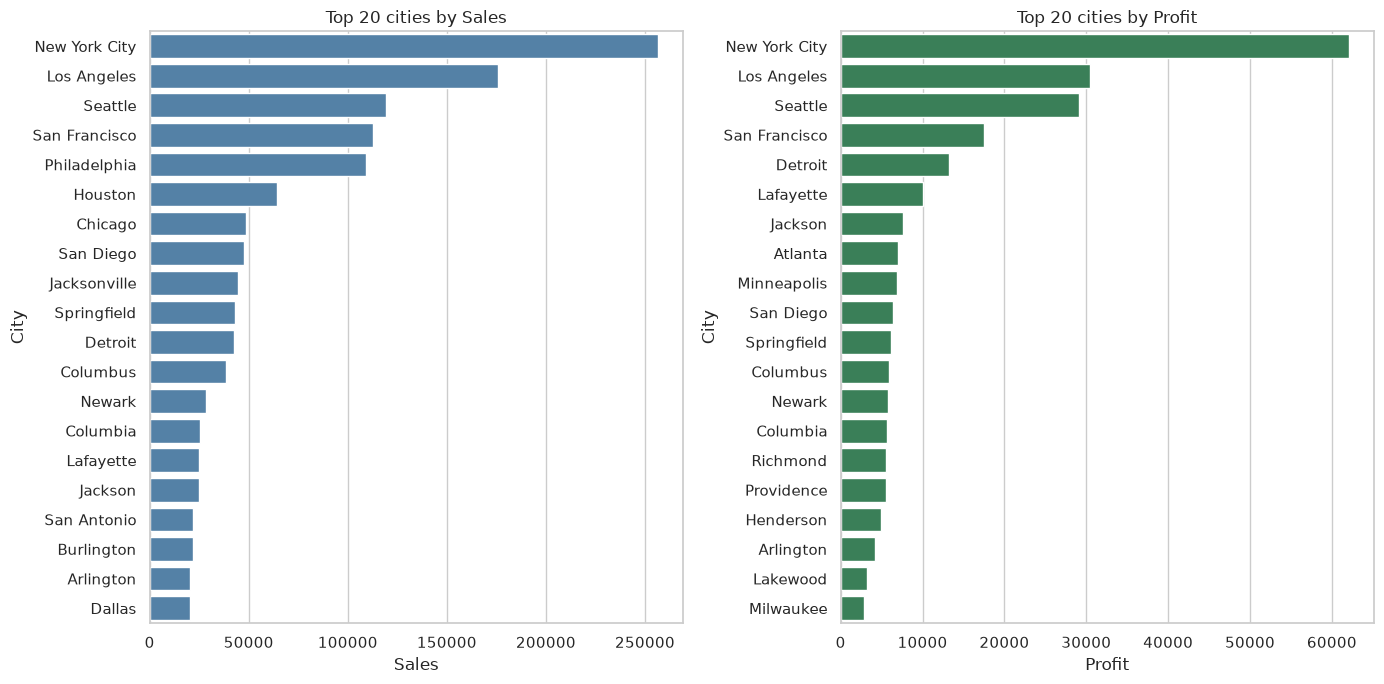

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
# two charts next to each other
sns.barplot(x=top_sales['Sales'], y=top_sales.index, color='steelblue', ax=axes[0])
# left: top 20 by sales; ax= tells seaborn which chart to draw on
axes[0].set_title('Top 20 cities by Sales')
# left title
sns.barplot(x=top_profit['Profit'], y=top_profit.index, color='seagreen', ax=axes[1])
# right: top 20 by profit
axes[1].set_title('Top 20 cities by Profit')
# right title
plt.tight_layout()
# tight_layout() stops the two charts from overlapping
plt.show()
# I display the charts

In [18]:
top_sales.round(1)
# the top 20 sales cities with their margin, to see which lose money

,Sales,Profit,Margin %
City,,,
New York City,256368.2,62037.0,24.2
Los Angeles,175851.3,30440.8,17.3
Seattle,119540.7,29156.1,24.4
San Francisco,112669.1,17507.4,15.5
Philadelphia,109077.0,-13837.8,-12.7
Houston,64504.8,-10153.5,-15.7
Chicago,48539.5,-6654.6,-13.7
San Diego,47521.0,6377.2,13.4
Jacksonville,44713.2,-2323.8,-5.2


**What the result shows:** New York City, Los Angeles, Seattle and San Francisco lead both lists. Only 13 cities are in both lists. Philadelphia (5th in sales), Houston, Chicago, San Antonio, Jacksonville, Burlington and Dallas sell a lot but **lose money**. Smaller cities like Lafayette, Atlanta and Minneapolis keep about 40% of their sales as profit.

## Step 9. Top 20 customers by Sales
**What I want to find:** the 20 biggest customers, and whether they are profitable.

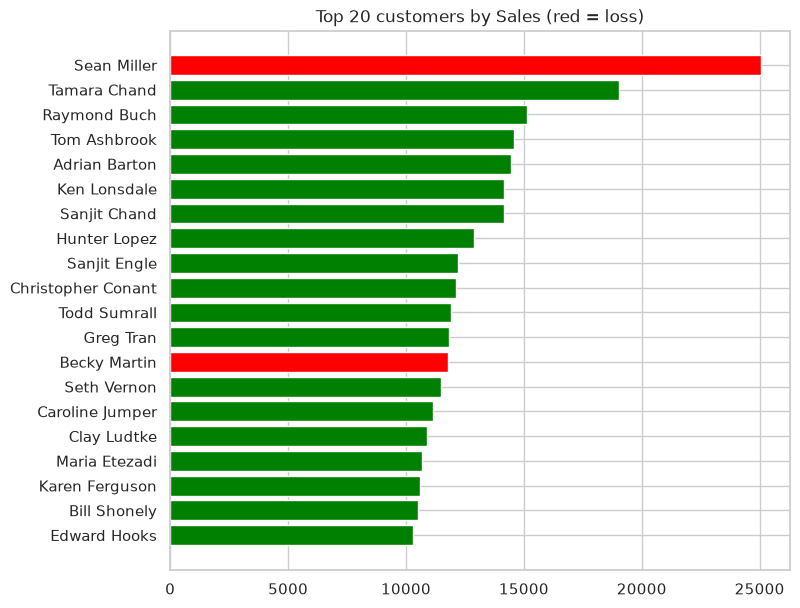

In [19]:
top_cust = cust.sort_values('Sales', ascending=False).head(20)
# the 20 customers with the most sales
colors = ['red' if p < 0 else 'green' for p in top_cust['Profit']]
# red if the customer makes a loss, green if a profit
plt.figure(figsize=(8, 7))
# chart size
plt.barh(top_cust.index, top_cust['Sales'], color=colors)
# horizontal bars of sales, colored by profit or loss
plt.gca().invert_yaxis()
# gca() = the current chart; invert_yaxis() puts the biggest customer on top
plt.title('Top 20 customers by Sales (red = loss)')
# chart title
plt.show()
# I display the chart

**What the result shows:** Sean Miller is the biggest customer (\$25,043) but he brings a loss (−\$1,981). Tamara Chand (\$19,052) and Raymond Buch (\$15,117) are big and very profitable.

## Step 10. Cumulative curve in Sales by Customers – Pareto for Sales?
**What I want to find:** what share of all sales the best 20% of customers bring.

47.96190899720081


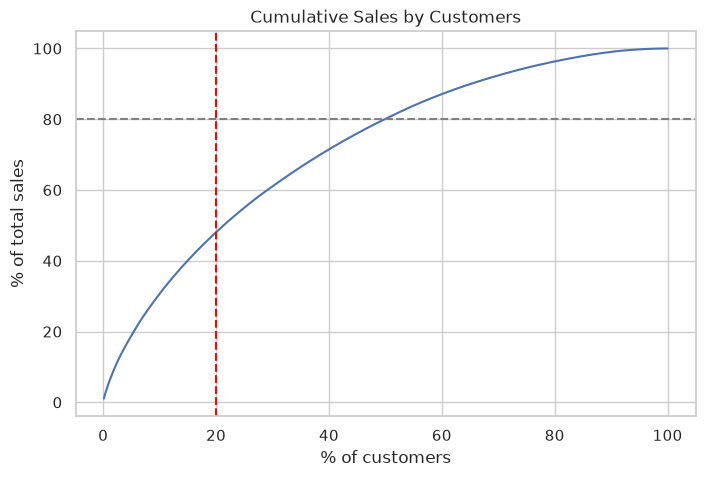

In [20]:
cust_sales = cust['Sales'].sort_values(ascending=False)
# customers' sales, biggest first
cum_sales = cust_sales.cumsum() / cust_sales.sum() * 100
# running total of sales, in percent
print(cum_sales.iloc[top20 - 1])
# the share of sales after the top 20% of customers
plt.figure(figsize=(8, 5))
# chart size
plt.plot(x, cum_sales.values)
# the line: % of customers vs % of sales (x is from step 7)
plt.axvline(20, color='red', linestyle='--')
# vertical line at 20% of customers
plt.axhline(80, color='gray', linestyle='--')
# horizontal line at 80%
plt.title('Cumulative Sales by Customers')
# chart title
plt.xlabel('% of customers')
# x-axis label
plt.ylabel('% of total sales')
# y-axis label
plt.show()
# I display the chart

**What the result shows:** no. The best 20% of customers bring only about 48% of the sales. Sales are spread much more evenly than profit, so the 80/20 rule does not work for sales.

## Step 11. My decisions: which states and cities to prioritize
**I would invest in (high sales and high profit):**
- **New York (New York City):** 2nd in sales, the best margin of the big states (23.8%), and home of the top customer Tom Ashbrook.
- **California (Los Angeles, San Francisco):** the biggest market, and profitable (16.7%).
- **Washington (Seattle):** 4th in sales with a 24% margin.
- **Michigan (Detroit) and Virginia:** smaller, but very profitable (32% and 26%).

**I would fix these before spending more on marketing:**
- **Texas (Houston, San Antonio, Dallas), Pennsylvania (Philadelphia), Illinois (Chicago), Ohio:** they sell a lot but lose money, so I would first check their discounts.

**Customers:** I would keep the best 20% of customers happy (they bring ~81% of the profit), and check big customers who bring a loss, like Sean Miller.